## 📓 Notebook 05: Early Stopping & Regularization

**Skills practiced:** `early_stopping_rounds`, `evals_result()`, plotting train vs. validation loss, `reg_alpha` / `reg_lambda`.

**Goal:** Mark where overfitting begins on a loss-curve plot, prove a forced full-length model does no better, and see how regularization changes the curve.

In [33]:
import time; 
import numpy as np
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_auc_score, accuracy_score, average_precision_score

In [34]:
y_train=pd.read_csv('../data/processed/y_train.csv')
y_test=pd.read_csv('../data/processed/y_test.csv')
y_val=pd.read_csv('../data/processed/y_val.csv')
x_train=pd.read_csv('../data/processed/train_enc.csv')
x_test=pd.read_csv('../data/processed/test_enc.csv')
x_val=pd.read_csv('../data/processed/validate_enc.csv')

In [35]:
m=xgb.XGBClassifier(early_stopping_rounds=20, n_jobs=-1)
m.fit(x_train, y_train, eval_set=[(x_train, y_train), (x_val, y_val)], verbose=False)
proba = m.predict_proba(x_test)[:, 1]

print("best_iteration:", m.best_iteration)
print("best AUC during fit:", round(m.best_score, 4))
print("test AUC:", round(roc_auc_score(y_test, proba), 4))
print("test PR-AUC:", round(average_precision_score(y_test, proba), 4))
print("test acc:", round(accuracy_score(y_test, m.predict(x_test)), 4))

train_loss=m.evals_result()['validation_0']['logloss']
validation_loss=m.evals_result()['validation_1']['logloss']

best_iteration: 7
best AUC during fit: 0.4491
test AUC: 0.8184
test PR-AUC: 0.6165
test acc: 0.7885


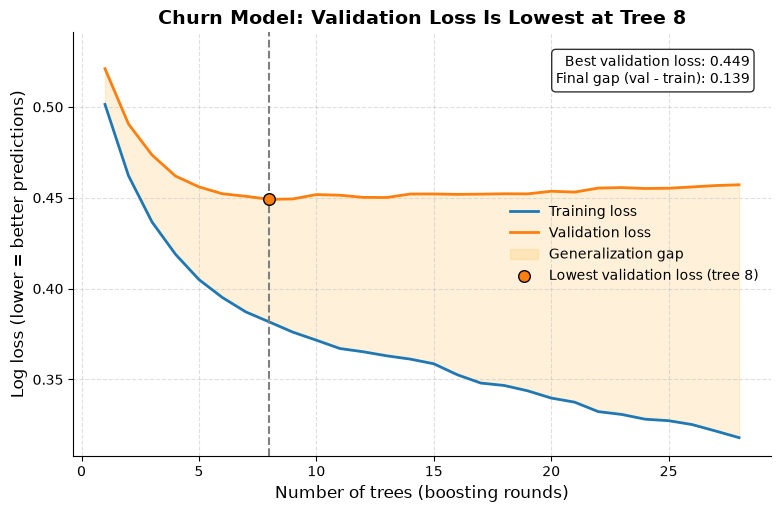

In [36]:
train = train_loss
val = validation_loss
trees = range(1, len(train) + 1)
best = val.index(min(val)) + 1
gap = val[-1] - train[-1]

fig, ax = plt.subplots(figsize=(9, 5.5))

# Two loss curves
ax.plot(trees, train, color="#1f77b4", linewidth=2, label="Training loss")
ax.plot(trees, val, color="#ff7f0e", linewidth=2, label="Validation loss")

# Shaded gap between the curves
ax.fill_between(trees, train, val, color="orange", alpha=0.15, label="Generalization gap")

# Best stopping point: dashed line plus a marker on the validation curve
ax.axvline(best, color="gray", linestyle="--", linewidth=1.5)
ax.scatter(best, min(val), color="#ff7f0e", edgecolor="black", s=70, zorder=3,
           label=f"Lowest validation loss (tree {best})")

# Key numbers in a corner box
ax.text(0.97, 0.95,
        f"Best validation loss: {min(val):.3f}\nFinal gap (val - train): {gap:.3f}",
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

# Titles and labels
ax.set_title(f"Churn Model: Validation Loss Is Lowest at Tree {best}",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Number of trees (boosting rounds)", fontsize=12)
ax.set_ylabel("Log loss (lower = better predictions)", fontsize=12)
ax.set_ylim(min(train) - 0.01, max(val) + 0.02)

# Clean look
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=10, loc="center right")

fig.savefig("../outputs/figures/xgb_train_val_logloss.png", dpi=300, bbox_inches="tight")
plt.show()

In [37]:
m2=xgb.XGBClassifier(n_estimators=21,n_jobs=-1)
m2.fit(x_train, y_train, eval_set=[(x_train, y_train), (x_val, y_val)], verbose=False)
proba = m2.predict_proba(x_test)[:, 1]

print("test AUC:", round(roc_auc_score(y_test, proba), 4))
print("test PR-AUC:", round(average_precision_score(y_test, proba), 4))
print("test acc:", round(accuracy_score(y_test, m2.predict(x_test)), 4))

test AUC: 0.8162
test PR-AUC: 0.6122
test acc: 0.7835


Computed the validation ROC-AUC without early stopping and it's almost equal, not better.

In [38]:
m3=xgb.XGBClassifier(early_stopping_rounds=30,  reg_alpha=1.0, reg_lambda=1.0, n_jobs=-1)
m3.fit(x_train, y_train, eval_set=[(x_train, y_train), (x_val, y_val)], verbose=False)
proba = m3.predict_proba(x_test)[:, 1]

print("best_iteration:", m3.best_iteration)
print("best AUC during fit:", round(m3.best_score, 4))
print("test AUC:", round(roc_auc_score(y_test, proba), 4))
print("test PR-AUC:", round(average_precision_score(y_test, proba), 4))
print("test acc:", round(accuracy_score(y_test, m3.predict(x_test)), 4))

validation_loss2=m3.evals_result()['validation_1']['logloss']

best_iteration: 9
best AUC during fit: 0.4533
test AUC: 0.8241
test PR-AUC: 0.6185
test acc: 0.7878


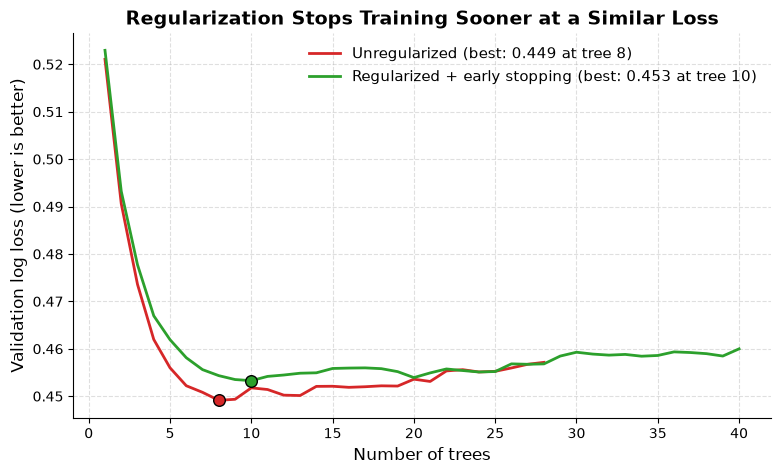

In [39]:
val_a = validation_loss      # unregularized model (m)
val_b = validation_loss2     # regularized + early stopping (m3)

best_a = val_a.index(min(val_a)) + 1
best_b = val_b.index(min(val_b)) + 1

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(range(1, len(val_a) + 1), val_a, color="#d62728", linewidth=2,
        label=f"Unregularized (best: {min(val_a):.3f} at tree {best_a})")
ax.plot(range(1, len(val_b) + 1), val_b, color="#2ca02c", linewidth=2,
        label=f"Regularized + early stopping (best: {min(val_b):.3f} at tree {best_b})")

ax.scatter(best_a, min(val_a), color="#d62728", edgecolor="black", s=70, zorder=3)
ax.scatter(best_b, min(val_b), color="#2ca02c", edgecolor="black", s=70, zorder=3)

ax.set_title("Regularization Stops Training Sooner at a Similar Loss", fontsize=14, fontweight="bold")
ax.set_xlabel("Number of trees", fontsize=12)
ax.set_ylabel("Validation log loss (lower is better)", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.4)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=11)

fig.savefig("../outputs/figures/xgb_compare_simple.png", dpi=300, bbox_inches="tight")
plt.show()